In [5]:
from google.colab import files
import pandas as pd

# Upload your downloaded IMDb CSV file
uploaded = files.upload()

# Read the uploaded file
filename = list(uploaded.keys())[0]

try:
    df = pd.read_csv(filename)
except UnicodeDecodeError:
    df = pd.read_csv(filename, encoding="latin-1")

print("File loaded:", filename)
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Saving IMDB Dataset.zip to IMDB Dataset.zip
File loaded: IMDB Dataset.zip
Dataset shape: (50000, 2)

Column names:
['review', 'sentiment']

First 5 rows:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


# Explore and clean the dataset

Missing values:
review       0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sentiment percentages:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64

Duplicate rows: 418
Duplicate reviews: 418

Review length statistics:
count    50000.000000
mean      1309.431020
std        989.728014
min         32.000000
25%        699.000000
50%        970.000000
75%       1590.250000
max      13704.000000
Name: review, dtype: float64

Cleaned dataset shape: (49582, 2)

Sentiment distribution after cleaning:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64

Cleaned review examples:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. The filming tec...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


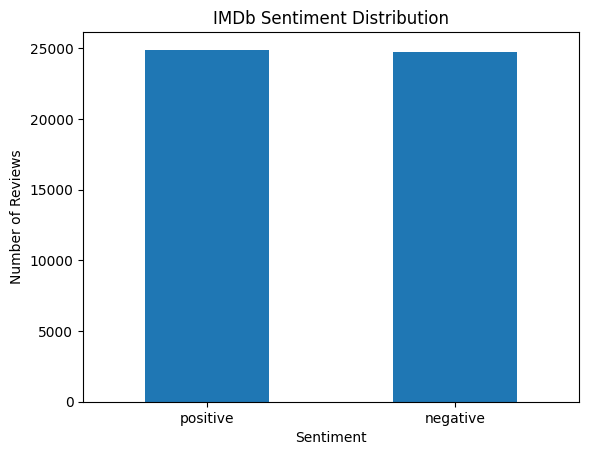

In [6]:
import pandas as pd
import re
import html
import matplotlib.pyplot as plt

# 1. Check missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Check sentiment distribution
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nSentiment percentages:")
print((df["sentiment"].value_counts(normalize=True) * 100).round(2))

# 3. Check duplicate rows and reviews
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate reviews:", df["review"].duplicated().sum())

# 4. Check review lengths
print("\nReview length statistics:")
print(df["review"].str.len().describe())

# 5. Remove missing values and duplicate rows
df = df.dropna(subset=["review", "sentiment"]).copy()
df["sentiment"] = df["sentiment"].str.strip().str.lower()
df = df.drop_duplicates(subset=["review"]).copy()

# 6. Clean HTML tags and HTML entities in reviews
def clean_review(text):
    text = html.unescape(str(text))
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["review"] = df["review"].apply(clean_review)

# 7. Keep only the expected sentiment labels
df = df[df["sentiment"].isin(["positive", "negative"])].copy()

# 8. Display the cleaned dataset
print("\nCleaned dataset shape:", df.shape)
print("\nSentiment distribution after cleaning:")
print(df["sentiment"].value_counts())

print("\nCleaned review examples:")
display(df[["review", "sentiment"]].head())

# 9. Plot sentiment distribution
df["sentiment"].value_counts().reindex(
    ["positive", "negative"]
).plot(kind="bar", rot=0)

plt.title("IMDb Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

# Split the data and convert reviews into TF-IDF features

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

import numpy as np

# 1. Separate input text and target labels
X = df["review"]
y = df["sentiment"]

# 2. Convert labels to numbers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Label mapping:")
for label, number in zip(label_encoder.classes_,
                         label_encoder.transform(label_encoder.classes_)):
    print(f"{label} = {number}")

# 3. Split into training and testing sets (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 4. Convert reviews into TF-IDF features
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    dtype=np.float32
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# 5. Display feature information
print("\nTF-IDF preprocessing completed!")
print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)
print("Number of TF-IDF features:", len(tfidf_vectorizer.get_feature_names_out()))

print("\nSample TF-IDF features:")
print(tfidf_vectorizer.get_feature_names_out()[:20])

Label mapping:
negative = 0
positive = 1

Training samples: 39665
Testing samples: 9917

TF-IDF preprocessing completed!
Training feature matrix: (39665, 5000)
Testing feature matrix: (9917, 5000)
Number of TF-IDF features: 5000

Sample TF-IDF features:
['00' '000' '10' '100' '11' '12' '13' '13th' '14' '15' '16' '17' '18'
 '1930' '1930s' '1939' '1940' '1950' '1950s' '1960']


# Train Logistic Regression

In [8]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Create the model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# 2. Measure training time
start_time = time.perf_counter()

lr_model.fit(X_train_tfidf, y_train)

training_time = time.perf_counter() - start_time

# 3. Predict sentiment on the test data
y_pred = lr_model.predict(X_test_tfidf)

# 4. Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# 5. Display results
print("===== LOGISTIC REGRESSION RESULTS =====")
print(f"Training Time: {training_time:.4f} seconds")
print(f"Testing Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

===== LOGISTIC REGRESSION RESULTS =====
Training Time: 0.9339 seconds
Testing Accuracy: 88.38%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.89      0.87      0.88      4940
    Positive       0.87      0.90      0.89      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917

Confusion Matrix:
[[4292  648]
 [ 504 4473]]


# Prepare the CPU vs GPU experiment

In [9]:
import torch
import numpy as np
import random

# Check available hardware
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. Check Runtime settings.")

# Set random seeds for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

print("\nTraining samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("TF-IDF features:", X_train_tfidf.shape[1])
print("Number of classes:", len(np.unique(y_train)))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU name: Tesla T4

Training samples: 39665
Testing samples: 9917
TF-IDF features: 5000
Number of classes: 2


# Check the GPU again

In [10]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU is still unavailable.")
    !nvidia-smi

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU name: Tesla T4


# Train the same neural network on CPU and GPU

In [11]:
import time
import copy
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report

# 1. Set experiment settings
INPUT_SIZE = X_train_tfidf.shape[1]  # 5000
HIDDEN_SIZE = 128
OUTPUT_SIZE = 2
EPOCHS = 5
BATCH_SIZE = 256
LEARNING_RATE = 0.001

device_gpu = torch.device("cuda")
device_cpu = torch.device("cpu")

# Convert labels to NumPy arrays
y_train_np = np.asarray(y_train, dtype=np.int64)
y_test_np = np.asarray(y_test, dtype=np.int64)


# 2. Define the neural network
class SentimentNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(INPUT_SIZE, HIDDEN_SIZE),
            nn.ReLU(),
            nn.Linear(HIDDEN_SIZE, OUTPUT_SIZE)
        )

    def forward(self, x):
        return self.network(x)


# 3. Create one initial model so both experiments start
# with exactly the same weights
torch.manual_seed(42)
initial_model = SentimentNN()
initial_weights = copy.deepcopy(initial_model.state_dict())

# Use the same shuffled batch order for both devices
rng = np.random.default_rng(42)
batch_orders = [
    rng.permutation(len(y_train_np))
    for _ in range(EPOCHS)
]


# 4. Function to train and evaluate on a chosen device
def run_experiment(device, experiment_name):
    model = SentimentNN().to(device)
    model.load_state_dict(initial_weights)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )

    model.train()

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    # Training loop
    for epoch in range(EPOCHS):
        order = batch_orders[epoch]

        for start in range(0, len(order), BATCH_SIZE):
            indices = order[start:start + BATCH_SIZE]

            # Convert only the current sparse batch to dense
            batch_x = X_train_tfidf[indices].toarray()
            batch_y = y_train_np[indices]

            batch_x = torch.from_numpy(
                batch_x.astype(np.float32, copy=False)
            ).to(device)

            batch_y = torch.from_numpy(batch_y).to(device)

            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.perf_counter() - start_time

    # Evaluate test data in batches
    model.eval()
    predictions = []

    with torch.no_grad():
        for start in range(0, X_test_tfidf.shape[0], BATCH_SIZE):
            end = min(start + BATCH_SIZE, X_test_tfidf.shape[0])

            batch_x = X_test_tfidf[start:end].toarray()
            batch_x = torch.from_numpy(
                batch_x.astype(np.float32, copy=False)
            ).to(device)

            outputs = model(batch_x)
            predictions.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )

    accuracy = accuracy_score(y_test_np, predictions)

    print(f"\n===== {experiment_name} RESULTS =====")
    print(f"Device: {device}")
    print(f"Training time: {training_time:.4f} seconds")
    print(f"Test accuracy: {accuracy * 100:.2f}%")
    print("\nClassification report:")
    print(classification_report(
        y_test_np,
        predictions,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        zero_division=0
    ))

    return {
        "device": experiment_name,
        "training_time": training_time,
        "accuracy": accuracy * 100
    }


# 5. Run both experiments
cpu_results = run_experiment(device_cpu, "CPU")
gpu_results = run_experiment(device_gpu, "GPU")


# 6. Compare results
import pandas as pd

comparison = pd.DataFrame([cpu_results, gpu_results])

print("\n===== CPU vs GPU COMPARISON =====")
display(comparison.round(4))

speedup = cpu_results["training_time"] / gpu_results["training_time"]

print(f"\nGPU speedup relative to CPU: {speedup:.2f}x")


===== CPU RESULTS =====
Device: cpu
Training time: 8.3349 seconds
Test accuracy: 88.03%

Classification report:
              precision    recall  f1-score   support

    Negative       0.88      0.88      0.88      4940
    Positive       0.88      0.88      0.88      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917


===== GPU RESULTS =====
Device: cuda
Training time: 2.7665 seconds
Test accuracy: 88.03%

Classification report:
              precision    recall  f1-score   support

    Negative       0.88      0.88      0.88      4940
    Positive       0.88      0.88      0.88      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917


===== CPU vs GPU COMPARISON =====


,device,training_time,accuracy
0,CPU,8.3349,88.0307
1,GPU,2.7665,88.0307



GPU speedup relative to CPU: 3.01x


### CPU vs GPU speedup graph

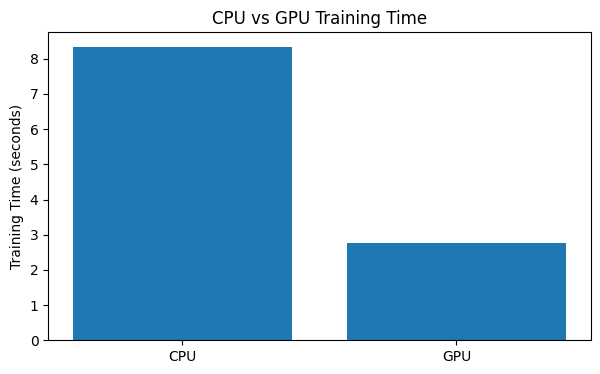

GPU Speedup: 3.01x


In [18]:

import matplotlib.pyplot as plt

devices = ["CPU", "GPU"]
times = [
    cpu_results["training_time"],
    gpu_results["training_time"]
]

plt.figure(figsize=(7, 4))
plt.bar(devices, times)

plt.ylabel("Training Time (seconds)")
plt.title("CPU vs GPU Training Time")
plt.show()

print(f"GPU Speedup: {speedup:.2f}x")


# Train Decision Tree

In [12]:
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Create the Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42
)

# 2. Measure training time
start_time = time.perf_counter()

dt_model.fit(X_train_tfidf, y_train)

dt_training_time = time.perf_counter() - start_time

# 3. Predict on test data
dt_pred = dt_model.predict(X_test_tfidf)

# 4. Calculate test accuracy
dt_accuracy = accuracy_score(y_test, dt_pred)

# 5. Display results
print("===== DECISION TREE RESULTS =====")
print(f"Training Time: {dt_training_time:.4f} seconds")
print(f"Testing Accuracy: {dt_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

===== DECISION TREE RESULTS =====
Training Time: 59.2591 seconds
Testing Accuracy: 71.31%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.71      0.72      0.71      4940
    Positive       0.72      0.71      0.71      4977

    accuracy                           0.71      9917
   macro avg       0.71      0.71      0.71      9917
weighted avg       0.71      0.71      0.71      9917

Confusion Matrix:
[[3536 1404]
 [1441 3536]]


### Confusion matrix graphs

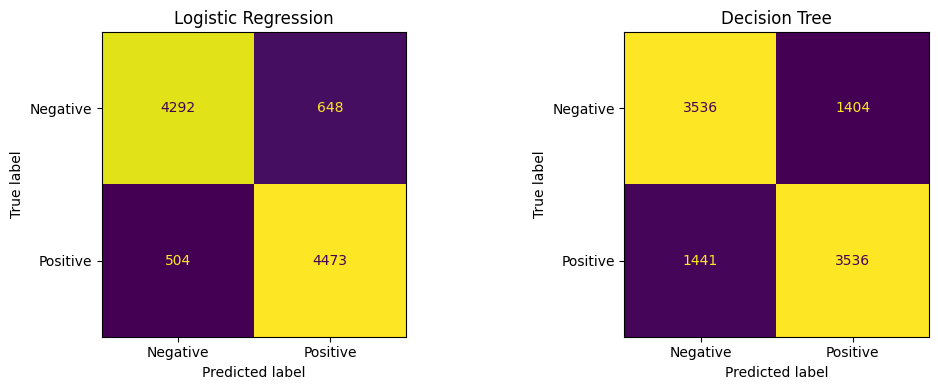

In [19]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Negative", "Positive"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test, dt_pred,
    display_labels=["Negative", "Positive"],
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Decision Tree")

plt.tight_layout()
plt.show()


# Compare both traditional ML models

===== ML MODEL COMPARISON =====


,Model,Test Accuracy (%),Training Time (seconds)
0,Logistic Regression,88.3836,0.9339
1,Decision Tree,71.3119,59.2591


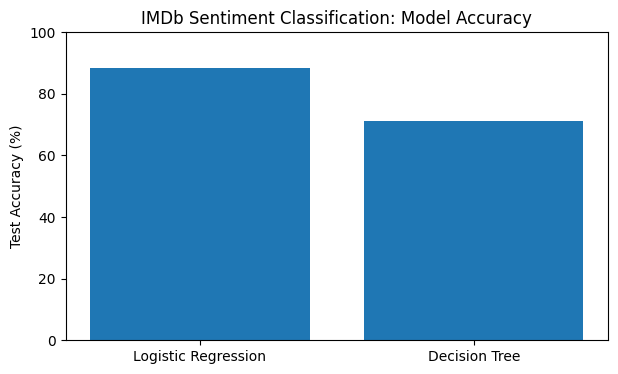

In [13]:
import pandas as pd

model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Test Accuracy (%)": accuracy * 100,
        "Training Time (seconds)": training_time
    },
    {
        "Model": "Decision Tree",
        "Test Accuracy (%)": dt_accuracy * 100,
        "Training Time (seconds)": dt_training_time
    }
])

print("===== ML MODEL COMPARISON =====")
display(model_comparison.round(4))

# Plot accuracy comparison
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.bar(
    model_comparison["Model"],
    model_comparison["Test Accuracy (%)"]
)
plt.ylabel("Test Accuracy (%)")
plt.title("IMDb Sentiment Classification: Model Accuracy")
plt.ylim(0, 100)
plt.show()

# Save both models for your backend

In [14]:
import joblib
import zipfile

joblib.dump(tfidf_vectorizer, "tfidf_vectorizer.pkl")
joblib.dump(lr_model, "logistic_regression_model.pkl")
joblib.dump(dt_model, "decision_tree_model.pkl")

model_comparison.to_csv("ml_model_comparison.csv", index=False)

with zipfile.ZipFile("imdb_project_models.zip", "w") as z:
    z.write("tfidf_vectorizer.pkl")
    z.write("logistic_regression_model.pkl")
    z.write("decision_tree_model.pkl")
    z.write("ml_model_comparison.csv")

print("All model files saved successfully!")

from google.colab import files
files.download("imdb_project_models.zip")

All model files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# five fold cross validation

In [17]:

import numpy as np
import pandas as pd
import time

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=40,
        min_samples_split=5,
        min_samples_leaf=2,
        criterion="entropy",
        random_state=42
    )
}

results = []

for name, model in models.items():

    print(f"\nEvaluating {name}...")

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            stop_words="english",
            dtype=np.float32
        )),
        ("model", model)
    ])

    start = time.perf_counter()

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=2
    )

    cv_time = time.perf_counter() - start

    start = time.perf_counter()

    pipeline.fit(X_train, y_train)

    fit_time = time.perf_counter() - start

    train_accuracy = accuracy_score(
        y_train,
        pipeline.predict(X_train)
    ) * 100

    test_accuracy = accuracy_score(
        y_test,
        pipeline.predict(X_test)
    ) * 100

    results.append({
        "Model": name,
        "Training Accuracy (%)": train_accuracy,
        "Mean CV Accuracy (%)":
            scores["test_score"].mean() * 100,
        "CV Std Dev (%)":
            scores["test_score"].std() * 100,
        "Testing Accuracy (%)": test_accuracy,
        "Final Fit Time (sec)": fit_time,
        "5-Fold CV Time (sec)": cv_time
    })

    print(
        "Fold validation accuracies:",
        np.round(scores["test_score"] * 100, 2)
    )

    print(f"Training accuracy: {train_accuracy:.2f}%")

    print(
        f"Mean CV accuracy: "
        f"{scores['test_score'].mean() * 100:.2f}%"
    )

    print(f"Testing accuracy: {test_accuracy:.2f}%")

results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
display(results_df.round(2))



Evaluating Logistic Regression...
Fold validation accuracies: [88.44 88.6  88.54 88.25 88.47]
Training accuracy: 91.06%
Mean CV accuracy: 88.46%
Testing accuracy: 88.38%

Evaluating Decision Tree...
Fold validation accuracies: [73.23 71.37 72.72 73.39 72.42]
Training accuracy: 92.05%
Mean CV accuracy: 72.63%
Testing accuracy: 73.59%

FINAL MODEL COMPARISON


,Model,Training Accuracy (%),Mean CV Accuracy (%),CV Std Dev (%),Testing Accuracy (%),Final Fit Time (sec),5-Fold CV Time (sec)
0,Logistic Regression,91.06,88.46,0.12,88.38,7.73,36.43
1,Decision Tree,92.05,72.63,0.72,73.59,40.52,138.96


### Training vs testing accuracy graph

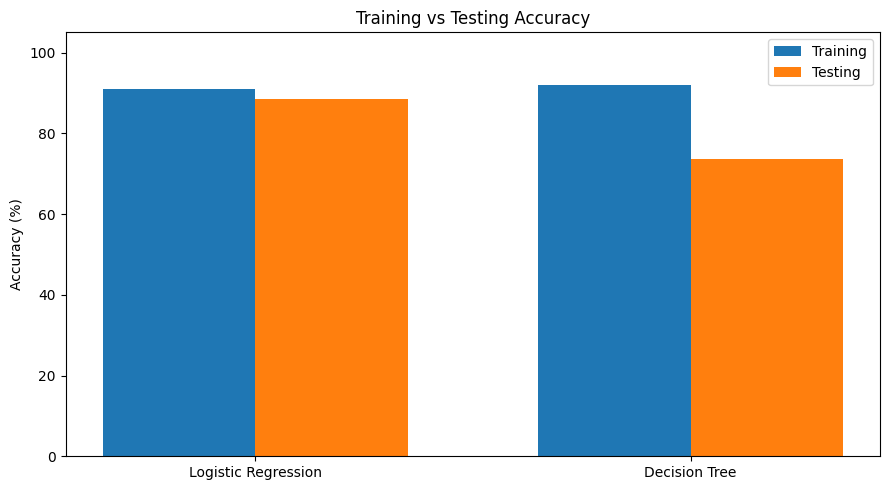

In [20]:

import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(results_df))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    results_df["Training Accuracy (%)"],
    width,
    label="Training"
)

plt.bar(
    x + width/2,
    results_df["Testing Accuracy (%)"],
    width,
    label="Testing"
)

plt.xticks(x, results_df["Model"])
plt.ylabel("Accuracy (%)")
plt.title("Training vs Testing Accuracy")
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()


In [21]:
print("X_train type:", type(X_train))
print("X_train shape:", X_train.shape)
print("First training sample:", str(X_train[0])[:200]
      if isinstance(X_train, list)
      else str(X_train.iloc[0])[:200]
      if hasattr(X_train, "iloc")
      else "Check the data format")

X_train type: <class 'pandas.core.series.Series'>
X_train shape: (39665,)
First training sample: I am one of Jehovah's Witnesses and I also work in an acute care medical facility. Over the years I have seen people die from hemolytic reactions to blood transfusions, have attended numerous conferen


In [22]:
%whos

Variable                 Type                      Data/Info
------------------------------------------------------------
BATCH_SIZE               int                       256
ConfusionMatrixDisplay   type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DecisionTreeClassifier   ABCMeta                   <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
EPOCHS                   int                       5
GridSearchCV             ABCMeta                   <class 'sklearn.model_sel<...>on._search.GridSearchCV'>
HIDDEN_SIZE              int                       128
INPUT_SIZE               int                       5000
LEARNING_RATE            float                     0.001
LabelEncoder             type                      <class 'sklearn.preproces<...>ing._label.LabelEncoder'>
LogisticRegression       type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OUTPUT_SIZE              int                       2
Pipeline      

In [23]:
%whos

Variable                 Type                      Data/Info
------------------------------------------------------------
BATCH_SIZE               int                       256
ConfusionMatrixDisplay   type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DecisionTreeClassifier   ABCMeta                   <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
EPOCHS                   int                       5
GridSearchCV             ABCMeta                   <class 'sklearn.model_sel<...>on._search.GridSearchCV'>
HIDDEN_SIZE              int                       128
INPUT_SIZE               int                       5000
LEARNING_RATE            float                     0.001
LabelEncoder             type                      <class 'sklearn.preproces<...>ing._label.LabelEncoder'>
LogisticRegression       type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OUTPUT_SIZE              int                       2
Pipeline      

In [24]:
import os

print(os.listdir("/content"))

['.config', 'decision_tree_model.pkl', 'ml_model_comparison.csv', 'imdb_project_models.zip', 'logistic_regression_model.pkl', 'tfidf_vectorizer.pkl', 'IMDB Dataset.zip', 'sample_data']
